In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Inline plotting ke liye
%matplotlib inline

# Datasets load karna
df_adult = pd.read_csv('adult (1).csv')
df_loan = pd.read_csv('loan-train (1).csv')
df_hotel = pd.read_csv('hotel_booking (1).csv')

print("Datasets loaded successfully!")

Datasets loaded successfully!


--- Adult Dataset Shape & Info ---
(48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K



--- Missing Values ---
age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

--- Summary Statistics ---


,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,"48,842.00","48,842.00","48,842.00","48,842.00","48,842.00","48,842.00"
mean,38.64,"189,664.13",10.08,"1,079.07",87.50,40.42
std,13.71,"105,604.03",2.57,"7,452.02",403.00,12.39
min,17.00,"12,285.00",1.00,0.00,0.00,1.00
25%,28.00,"117,550.50",9.00,0.00,0.00,40.00
50%,37.00,"178,144.50",10.00,0.00,0.00,40.00
75%,48.00,"237,642.00",12.00,0.00,0.00,45.00
max,90.00,"1,490,400.00",16.00,"99,999.00","4,356.00",99.00


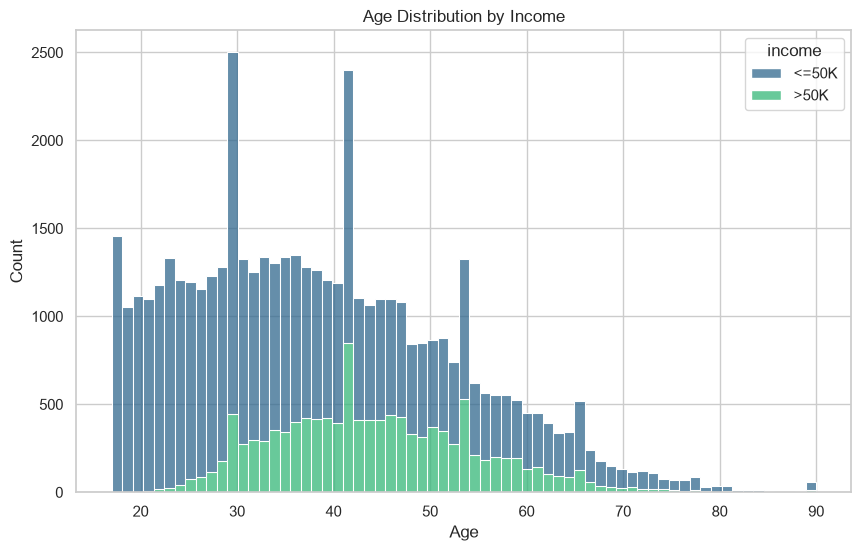

In [9]:
# 1. Basic Info & Shape
print("--- Adult Dataset Shape & Info ---")
print(df_adult.shape)
display(df_adult.head())

# 2. Missing Values Check
print("\n--- Missing Values ---")
print(df_adult.isnull().sum())

# 3. Summary Statistics
print("\n--- Summary Statistics ---")
display(df_adult.describe())

# 4. Visualization: Age distribution by Income
plt.figure(figsize=(10, 6))
sns.histplot(data=df_adult, x='age', hue='income', multiple='stack', palette='viridis')
plt.title('Age Distribution by Income')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

--- Loan Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   1600 non-null   float64
 10  Credit_History     1564 non-null   float64
 11  Property_Area      1614 non-null   str    
 12  Loan_Status        1614 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 221.3 KB
None

Missing Values:
Loan_ID               0
Gender               13
Married               3
Depe

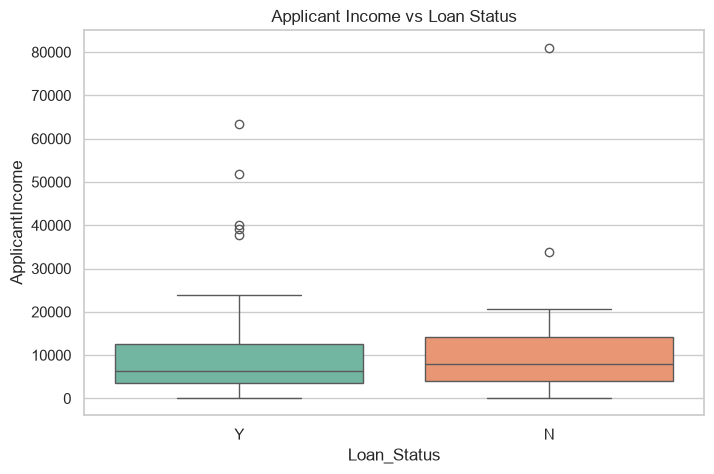

In [10]:
# 1. Basic Info & Missing Values
print("--- Loan Dataset Info ---")
print(df_loan.info())
print("\nMissing Values:")
print(df_loan.isnull().sum())

# 2. Handling Missing Values
# Numerical columns mein median ya mean se fill karein, categorical mein mode se
df_loan['LoanAmount'].fillna(df_loan['LoanAmount'].median(), inplace=True)
df_loan['Loan_Amount_Term'].fillna(df_loan['Loan_Amount_Term'].mode()[0], inplace=True)
df_loan['Credit_History'].fillna(df_loan['Credit_History'].mode()[0], inplace=True)
df_loan['Gender'].fillna(df_loan['Gender'].mode()[0], inplace=True)
df_loan['Married'].fillna(df_loan['Married'].mode()[0], inplace=True)
df_loan['Dependents'].fillna(df_loan['Dependents'].mode()[0], inplace=True)
df_loan['Self_Employed'].fillna(df_loan['Self_Employed'].mode()[0], inplace=True)

print("\nMissing values after cleaning:", df_loan.isnull().sum().sum())

# 3. Visualization: Loan Status vs Applicant Income
plt.figure(figsize=(8, 5))
sns.boxplot(x='Loan_Status', y='ApplicantIncome', data=df_loan, palette='Set2')
plt.title('Applicant Income vs Loan Status')
plt.show()

--- Hotel Booking Dataset Shape ---
(119390, 36)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734



--- Cancellation Percentage ---
is_canceled
0   62.96
1   37.04
Name: proportion, dtype: float64


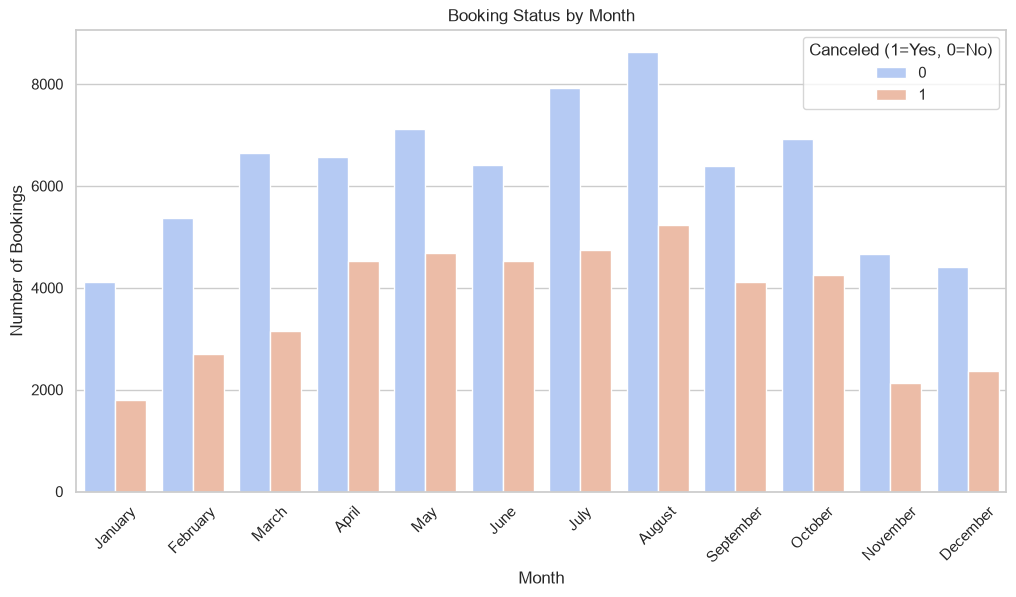

In [11]:
# 1. Basic Info
print("--- Hotel Booking Dataset Shape ---")
print(df_hotel.shape)
display(df_hotel.head(3))

# 2. Cancellation Rate Calculation
cancel_count = df_hotel['is_canceled'].value_counts(normalize=True) * 100
print("\n--- Cancellation Percentage ---")
print(cancel_count)

# 3. Visualization: Monthly Bookings & Cancellations
plt.figure(figsize=(12, 6))
sns.countplot(data=df_hotel, x='arrival_date_month', hue='is_canceled', 
              order=['January', 'February', 'March', 'April', 'May', 'June', 
                     'July', 'August', 'September', 'October', 'November', 'December'],
              palette='coolwarm')
plt.title('Booking Status by Month')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=45)
plt.legend(title='Canceled (1=Yes, 0=No)')
plt.show()